# Does the change-point method find real changes? Validation on Amazon Reviews 2023

Real Deal (the Chrome extension) groups review sentences into **themes** and tests whether the share of
reviews mentioning each theme **changed at some point in time**. On amazon.in we can only collect a few hundred
recent reviews per product, so we rarely see a significant change. That says little about whether the method
works.

This notebook re-implements the same pipeline in Python and runs it on **complete review histories**
(years per product) from the public McAuley Lab dataset, to answer:

1. **Is the test honest?** With no real change, how often does it raise a false alarm? *(simulation)*
2. **How sensitive is it?** How large a shift is detected, and with how many reviews? *(simulation)*
3. **Does it find real things?** On 50 real products, which changes does it flag, and do the reviews around each
   change point show that something actually happened? *(manual reading)*
4. **Ranking constants.** What prior mean and per-review spread should the v2 ranking score use?
5. **Stability.** Do the themes stay the same when the random seed or the sample changes? *(DECISIONS #24)*

**Data:** `All_Beauty` reviews (701,528 reviews; amazon.com, May 1996 – Sep 2023), file
`research/data/All_Beauty.jsonl.gz` from `mcauleylab.ucsd.edu`. Everything is seeded (`SEED = 42`).

In [1]:
import gzip, html, json, re, math, time, warnings
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import xlogy
from scipy.stats import norm
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import torch
from sentence_transformers import SentenceTransformer

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 120)

SEED = 42
DATA = Path("data/All_Beauty.jsonl.gz")
MIN_REVIEWS, MIN_MONTHS = 300, 12      # product eligibility (as in the plan)
N_PRODUCTS = 50                        # products analysed in section 4
MIN_BUCKET_N, MIN_SIDE = 15, 30        # same constants as the extension (CLAUDE.md B1, B3)
B = 999                                # permutations for real products
FDR_Q = 0.10
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
rng = np.random.default_rng(SEED)
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

device: cuda NVIDIA GeForce GTX 1650


## 1. Data: products with long review histories

We stream the compressed file once, count reviews and the time span per product (`parent_asin`, which groups
colour/size variants like amazon.in does), and keep products with **≥ 300 reviews spanning ≥ 12 months**.

In [2]:
count, first, last = defaultdict(int), {}, {}
with gzip.open(DATA, "rt", encoding="utf-8") as f:
    for line in f:
        r = json.loads(line)
        a, t = r["parent_asin"], r["timestamp"] / 1000
        count[a] += 1
        first[a] = min(first.get(a, t), t)
        last[a] = max(last.get(a, t), t)

span_months = {a: (last[a] - first[a]) / (86400 * 30.44) for a in count}
eligible = sorted([a for a in count if count[a] >= MIN_REVIEWS and span_months[a] >= MIN_MONTHS], key=lambda a: -count[a])
print(f"{sum(count.values()):,} reviews, {len(count):,} products; eligible: {len(eligible)}")

def clean(s):
    # The dump keeps Amazon's HTML: <br /> line breaks and entities like &#34; ("br" became a theme word).
    s = re.sub(r"<br\s*/?>", "\n", s or "", flags=re.I)
    s = re.sub(r"<[^>]+>", " ", s)
    return html.unescape(s).strip()

# Load reviews of eligible products only (cleaned).
keep = set(eligible)
rows = []
with gzip.open(DATA, "rt", encoding="utf-8") as f:
    for line in f:
        r = json.loads(line)
        if r["parent_asin"] in keep:
            rows.append((r["parent_asin"], r.get("user_id"), r["timestamp"], r["rating"], clean(r.get("title")),
                         clean(r.get("text")), r.get("verified_purchase"), r.get("helpful_vote", 0)))
reviews = pd.DataFrame(rows, columns=["asin", "user", "ts", "rating", "title", "text", "verified", "helpful"])
# Exact duplicates (same product, reviewer, time and text) appear in the dump; keep one.
before_dedup = len(reviews)
reviews = reviews.drop_duplicates(subset=["asin", "user", "ts", "title", "text"])
print(f"removed {before_dedup - len(reviews):,} exact duplicate reviews")
reviews["date"] = pd.to_datetime(reviews["ts"], unit="ms").dt.normalize()
reviews = reviews.sort_values(["asin", "date", "ts"]).reset_index(drop=True)
reviews["review_id"] = np.arange(len(reviews))

per = reviews.groupby("asin").agg(n=("rating", "size"), mean_rating=("rating", "mean"),
                                  first=("date", "min"), last=("date", "max"))
per["months"] = ((per["last"] - per["first"]).dt.days / 30.44).round(0)
per.describe().round(2)

701,528 reviews, 112,565 products; eligible: 125


removed 629 exact duplicate reviews


,n,mean_rating,first,last,months
count,125.00,125.00,125,125,125.00
mean,522.23,4.06,2016-02-17 03:38:52.800000,2022-08-02 03:50:24,77.43
min,295.00,1.53,2005-10-08 00:00:00,2017-02-09 00:00:00,12.00
25%,332.00,3.85,2014-06-04 00:00:00,2022-04-16 00:00:00,50.00
50%,404.00,4.14,2016-08-04 00:00:00,2023-04-05 00:00:00,71.00
75%,554.00,4.45,2018-07-22 00:00:00,2023-07-09 00:00:00,98.00
max,1952.00,4.84,2022-07-29 00:00:00,2023-09-08 00:00:00,209.00
std,312.68,0.52,NaN,NaN,40.52


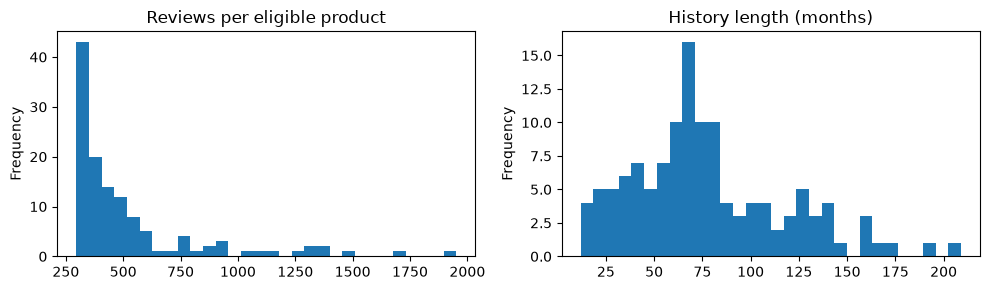

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
per["n"].plot.hist(bins=30, ax=ax[0], title="Reviews per eligible product")
per["months"].plot.hist(bins=30, ax=ax[1], title="History length (months)")
plt.tight_layout(); plt.show()

## 2. The method, step by step

All steps mirror the extension (`src/themes/*`, `src/stats/*`); constants are the same.

**2.1 Sentences.** Review title + body are split on `. ! ?` and line breaks; pieces with fewer than 3 words are
dropped.

**2.2 Embeddings.** Each sentence $s$ becomes a vector $v_s \in \mathbb{R}^{384}$ from all-MiniLM-L6-v2 (mean
pooling, normalised to $\lVert v_s \rVert = 1$). For unit vectors the cosine similarity is the dot product
$\cos(u,v) = u \cdot v$.

**2.3 Themes (k-means, k by silhouette).** For $k = 3,\dots,8$ run k-means on the unit vectors (10 restarts,
seeded). On the unit sphere, squared Euclidean distance is $\lVert u - v \rVert^2 = 2 - 2\,u\cdot v$, so
Euclidean k-means groups by cosine similarity. Choose the $k$ with the highest mean **silhouette**
$$s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}},$$
where $a(i)$ is the mean cosine distance $1 - u\cdot v$ from sentence $i$ to the others in its cluster and $b(i)$
the smallest mean distance to another cluster (computed on a seeded sample of 500 sentences).

**2.4 Labels (c-TF-IDF).** With $\mathrm{tf}(t,c)$ the count of word $t$ in cluster $c$, $f(t)$ its total count,
and $A$ the mean number of words per cluster: $w(t,c) = \mathrm{tf}(t,c)\cdot\log\!\big(1 + A/f(t)\big)$.
Top 3 words, stop words removed.

**2.5 Review-level indicator.** For theme $j$ and review $i$: $x_i = 1$ if any sentence of review $i$ is in
cluster $j$, else 0.

**2.6 Monthly buckets.** Reviews are grouped by calendar month and adjacent months are merged until every
bucket has $n \ge 15$ (a thin last bucket joins the previous one).

**2.7 Change-point scan.** Candidate split points $\tau$ are bucket boundaries with at least 30 reviews on
each side. With $k_1$ of $n_1$ reviews before $\tau$ mentioning the theme and $k_2$ of $n_2$ after, and the
binomial log-likelihood at its maximum $\ell(k,n) = k\log\frac{k}{n} + (n-k)\log\frac{n-k}{n}$ ($0\log 0 = 0$):
$$\mathrm{LR}(\tau) = \ell(k_1,n_1) + \ell(k_2,n_2) - \ell(k_1+k_2,\,n_1+n_2), \qquad T = \max_\tau \mathrm{LR}(\tau).$$

**2.8 Permutation p-value.** Under "no change" the order of the $x_i$ in time is arbitrary. Shuffle the $x_i$
across reviews (dates fixed) $B = 999$ times, recompute $T_b$, and
$p = \dfrac{1 + \#\{b : T_b \ge T\}}{B + 1}$. This accounts for having searched over all $\tau$.

The dataset holds **every** review of each product, so the star mix is the natural one and the plain
(unstratified) test applies (DECISIONS #35).

**2.9 Many themes: Benjamini–Hochberg.** For one product's $m$ themes with p-values sorted
$p_{(1)}\le\dots\le p_{(m)}$: $q_{(i)} = \min_{j\ge i} \frac{m\,p_{(j)}}{j}$, capped at 1. A theme has a
**detected change** if $q \le 0.10$.

In [4]:
STOP = set("""a about above after again against all also am an and any are as at be because been before being below
between both but by can could did do does doing done down during each few for from further get got had has have having
he her here hers herself him himself his how i if in into is it its itself just let me more most my myself no nor not now
of off on once one only or other our ours ourselves out over own same she should so some such than that the their theirs
them themselves then there these they this those through to too under until up us very was we were what when where which
while who whom why will with would you your yours yourself yourselves im ive dont didnt doesnt isnt wasnt cant wont
really even much many well product item amazon buy bought purchase purchased use used using""".split())

def split_sentences(text):
    parts = re.split(r"(?<=[.!?])\s+|\n+|(?<=[.!?])(?=[A-Za-z])", text or "")
    return [p.strip() for p in parts if len(re.findall(r"\w+", p)) >= 3]

def tokenize(s):
    return [w for w in re.findall(r"[a-z]{2,}", s.lower().replace("'", "")) if w not in STOP]

def ctfidf(docs, top=3):
    tf = [defaultdict(int) for _ in docs]
    for c, sents in enumerate(docs):
        for s in sents:
            for w in tokenize(s):
                tf[c][w] += 1
    f = defaultdict(int)
    for m in tf:
        for w, n in m.items():
            f[w] += n
    A = sum(f.values()) / max(1, len(docs))
    out = []
    for m in tf:
        scored = sorted(((n * math.log(1 + A / f[w]), w) for w, n in m.items()), key=lambda x: (-x[0], x[1]))
        out.append([w for _, w in scored[:top]])
    return out

def cluster(V, seed=SEED, kmin=3, kmax=8, restarts=10):
    """k-means on unit vectors, k by mean cosine silhouette on a seeded sample of <= 500."""
    best = None
    sample = min(500, len(V))
    for k in range(kmin, min(kmax, len(V) - 1) + 1):
        km = KMeans(n_clusters=k, n_init=restarts, random_state=seed).fit(V)
        s = silhouette_score(V, km.labels_, metric="cosine", sample_size=sample, random_state=seed)
        if best is None or s > best[1]:
            best = (k, s, km.labels_, km.cluster_centers_)
    return best

def buckets(dates, min_n=MIN_BUCKET_N):
    """Monthly buckets merged to n >= min_n. Returns list of (start_index, end_index) on date-sorted reviews."""
    months = dates.dt.to_period("M").to_numpy()
    edges, start = [], 0
    for i in range(1, len(months) + 1):
        if i == len(months) or months[i] != months[i - 1]:
            if i - start >= min_n or i == len(months):
                edges.append((start, i)); start = i
    if len(edges) > 1 and edges[-1][1] - edges[-1][0] < min_n:   # thin last bucket joins the previous one
        s, _ = edges[-2]; edges = edges[:-2] + [(s, edges[-1][1])]
    return edges

def lr_scan(X, taus):
    """X: (R, N) 0/1 rows (date-ordered). Returns max over taus of the binomial LR, per row, and argmax."""
    N = X.shape[1]
    cs = np.cumsum(X, axis=1)
    K = cs[:, -1:]
    t = np.asarray(taus)
    kb = cs[:, t - 1]
    ka = K - kb
    ll = lambda k, n: xlogy(k, k / n) + xlogy(n - k, (n - k) / n)
    lr = ll(kb, t) + ll(ka, N - t) - ll(K, N)
    return lr.max(axis=1), t[lr.argmax(axis=1)]

def change_point_test(x, edges, B=B, rng=rng, min_side=MIN_SIDE):
    N = len(x)
    taus = [s for s, _ in edges[1:] if s >= min_side and N - s >= min_side]
    if not taus:
        return None
    T, tau = lr_scan(x[None, :].astype(float), taus)
    perm = rng.permuted(np.tile(x.astype(float), (B, 1)), axis=1)
    Tb, _ = lr_scan(perm, taus)
    p = (1 + np.sum(Tb >= T[0] - 1e-9)) / (B + 1)
    return dict(T=float(T[0]), tau=int(tau[0]), p=float(p))

def bh(p):
    p = np.asarray(p, float); m = len(p)
    if m == 0:
        return p
    order = np.argsort(p)
    q = np.empty(m); running = 1.0
    for rank in range(m, 0, -1):
        i = order[rank - 1]
        running = min(running, m * p[i] / rank); q[i] = min(1.0, running)
    return q

# Hand-check against the extension's unit tests (tests/stats/*.test.ts):
x_step = np.r_[np.zeros(30), np.ones(30)]
print("LR perfect step =", round(lr_scan(x_step[None], [30])[0][0], 6), "(extension test: 41.588831)")
print("BH [0.01,0.04,0.03,0.005] ->", bh([0.01, 0.04, 0.03, 0.005]), "(extension test: [0.02, 0.04, 0.04, 0.02])")

LR perfect step = 41.588831 (extension test: 41.588831)
BH [0.01,0.04,0.03,0.005] -> [0.02 0.04 0.04 0.02] (extension test: [0.02, 0.04, 0.04, 0.02])


## 3. Simulations: false alarms and power

Each simulated product has $n$ reviews spread evenly over 12 months. Each review mentions the theme with
probability $p_0$ in months 1–6 and $p_1$ in months 7–12. **False-alarm rate** = share of runs with $p \le 0.05$
when $p_1 = p_0$; **power** = the same share when $p_1 \ne p_0$. 500 runs per cell; $B = 499$ permutations
per run (to keep the runtime short; the minimum p-value is then 1/500).

In [5]:
def simulate(n, p0, p1, reps=500, Bsim=499, seed=SEED):
    g = np.random.default_rng(seed + int(1000 * p1) + n)
    month = np.floor(np.arange(n) * 12 / n).astype(int)
    dates = pd.Series(pd.to_datetime([f"2022-{m + 1:02d}-15" for m in month]))
    edges = buckets(dates)
    hits = 0
    for _ in range(reps):
        x = (g.random(n) < np.where(month < 6, p0, p1)).astype(float)
        res = change_point_test(x, edges, B=Bsim, rng=g)
        hits += bool(res and res["p"] <= 0.05)
    return hits / reps

t0 = time.time()
sizes = [100, 150, 300, 600]
shifts = [0.10, 0.15, 0.20, 0.25, 0.30]
power = pd.DataFrame({n: [simulate(n, 0.10, p1) for p1 in shifts] for n in sizes},
                     index=[f"0.10 → {p1:.2f}" for p1 in shifts])
print(f"{time.time() - t0:.0f} s")
power.round(3)

45 s


,100,150,300,600
0.10 → 0.10,0.054,0.044,0.056,0.046
0.10 → 0.15,0.090,0.106,0.160,0.262
0.10 → 0.20,0.210,0.298,0.580,0.834
0.10 → 0.25,0.428,0.532,0.850,0.986
0.10 → 0.30,0.636,0.790,0.974,1.000


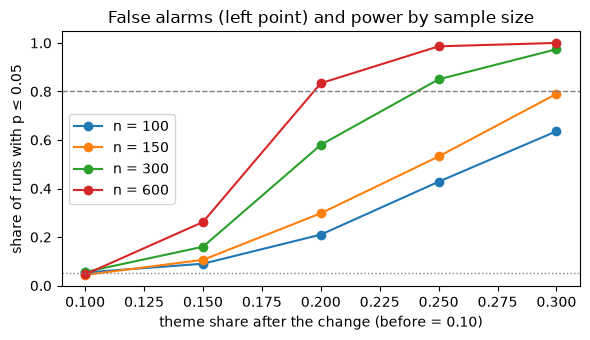

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for n in sizes:
    ax.plot(shifts, power[n].values, marker="o", label=f"n = {n}")
ax.axhline(0.05, color="grey", ls=":", lw=1); ax.axhline(0.80, color="grey", ls="--", lw=1)
ax.set_xlabel("theme share after the change (before = 0.10)"); ax.set_ylabel("share of runs with p ≤ 0.05")
ax.set_title("False alarms (left point) and power by sample size"); ax.legend(); plt.tight_layout(); plt.show()

**Reading the curves.** The left-most point of each line ($0.10 \to 0.10$, no change) is the false-alarm rate
and should sit near the dotted 5% line. The dashed line is 80% power: shifts to the right of where a curve
crosses it are detected reliably. Compare with the extension's own simulation table in `docs/METHODOLOGY.md`.

## 4. Real products: which changes are detected?

We take a seeded random sample of 50 eligible products, embed all their sentences on the GPU, find themes per
product, and test every theme. For each **detected change** ($q \le 0.10$) we print the theme's keywords, the
shares before/after, and **the 5 theme-mentioning reviews just before and just after the change point**, so a
person can judge whether something real happened (a formula change, a new batch, fakes, a listing merge…).

In [7]:
sample = list(rng.choice(eligible, size=min(N_PRODUCTS, len(eligible)), replace=False))
sub = reviews[reviews["asin"].isin(sample)].copy()

sent_rows = []
for rid, title, text in zip(sub["review_id"], sub["title"], sub["text"]):
    for j, s in enumerate(split_sentences(f"{title}.\n{text}")):
        sent_rows.append((rid, j, s))
sents = pd.DataFrame(sent_rows, columns=["review_id", "j", "text"])
print(f"{len(sample)} products, {len(sub):,} reviews, {len(sents):,} sentences")

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
t0 = time.time()
E = model.encode(sents["text"].tolist(), batch_size=256, normalize_embeddings=True, convert_to_numpy=True,
                 show_progress_bar=False)
print(f"embedded on {DEVICE} in {time.time() - t0:.1f} s, shape {E.shape}")
sents["asin"] = sents["review_id"].map(sub.set_index("review_id")["asin"])

50 products, 24,507 reviews, 81,496 sentences


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

embedded on cuda in 53.9 s, shape (81496, 384)


In [8]:
def analyze(asin, seed=SEED, B=B):
    rv = sub[sub["asin"] == asin].sort_values(["date", "ts"]).reset_index(drop=True)
    sm = sents[sents["asin"] == asin]
    V = E[sm.index.to_numpy()]
    k, sil, labels, _ = cluster(V, seed=seed)
    docs = [sm["text"].to_numpy()[labels == c].tolist() for c in range(k)]
    terms = ctfidf(docs)
    edges = buckets(rv["date"])
    g = np.random.default_rng(seed)
    out = []
    for c in range(k):
        mention = set(sm["review_id"].to_numpy()[labels == c])
        x = rv["review_id"].isin(mention).to_numpy().astype(float)
        res = change_point_test(x, edges, B=B, rng=g)
        if res is None:
            continue
        tau = res["tau"]
        out.append(dict(asin=asin, theme=c, label=", ".join(terms[c]), n=len(rv), k=k, silhouette=round(sil, 3),
                        change_at=rv["date"].iloc[tau].strftime("%Y-%m"), before=x[:tau].mean(), after=x[tau:].mean(),
                        n_before=tau, n_after=len(rv) - tau, p=res["p"], x_arr=x, tau_idx=tau))
    q = bh([o["p"] for o in out])
    for o, qi in zip(out, q):
        o["q"] = qi; o["detected"] = qi <= FDR_Q
    return out, rv

t0 = time.time()
results, frames = [], {}
for a in sample:
    out, rv = analyze(a)
    results += out; frames[a] = rv
res = pd.DataFrame(results)
print(f"analysed in {time.time() - t0:.0f} s: {res['asin'].nunique()} products, {len(res)} themes tested, "
      f"{int(res['detected'].sum())} detected changes in {res.loc[res.detected, 'asin'].nunique()} products")
cols = ["asin", "label", "n", "change_at", "before", "after", "p", "q"]
res.loc[res.detected, cols].sort_values("q").round(3)

analysed in 87 s: 50 products, 321 themes tested, 86 detected changes in 33 products


,asin,label,n,change_at,before,after,p,q
238,B01AYTGWA8,"smell, natural, like",309,2016-05,0.737,0.369,0.001,0.001
236,B01AYTGWA8,"review, works, work",309,2016-12,0.798,0.557,0.001,0.001
237,B01AYTGWA8,"polish, nail, remover",309,2016-05,0.940,0.784,0.001,0.001
158,B01I2MU2JQ,"pump, bottle, comes",434,2017-03,0.430,0.169,0.001,0.001
159,B01I2MU2JQ,"oil, coconut, oils",434,2017-01,0.771,0.480,0.001,0.001
...,...,...,...,...,...,...,...,...
251,B09FR54XLC,"return, months, working",468,2017-03,0.342,0.471,0.047,0.094
47,B097BSKSQW,"scent, smell, smells",401,2020-04,0.129,0.268,0.012,0.096
293,B005BZQHEC,"stretching, stretch, makes",772,2016-10,0.283,0.120,0.086,0.098
297,B005BZQHEC,"stuff, love, recommend",772,2014-08,0.372,0.279,0.075,0.098


### 4.1 Reviews around each detected change (for manual reading)

For each detected change: 5 reviews that mention the theme **just before** the change point and 5 **just after**
(stars, date, first 220 characters). Read them and ask: *did something about the product, the seller or the
listing change at that time, or is this ordinary variation?*

In [9]:
def around(row, k=5):
    rv, x, tau = frames[row.asin], row.x_arr, row.tau_idx
    idx_before = [i for i in range(tau - 1, -1, -1) if x[i] == 1][:k][::-1]
    idx_after = [i for i in range(tau, len(x)) if x[i] == 1][:k]
    fmt = lambda i: f"  {rv.loc[i, 'date']:%Y-%m-%d} {int(rv.loc[i, 'rating'])}★  " + \
        (rv.loc[i, "title"] + " — " + rv.loc[i, "text"]).replace("\n", " ")[:220]
    return "\n".join(["BEFORE:"] + [fmt(i) for i in idx_before] + ["AFTER:"] + [fmt(i) for i in idx_after])

for row in res[res.detected].sort_values("q").itertuples():
    print("=" * 110)
    print(f"{row.asin} | theme [{row.label}] | {row.before:.0%} → {row.after:.0%} from {row.change_at} "
          f"| n = {row.n} | p = {row.p:.3f}, q = {row.q:.3f}")
    print(around(row))

B01AYTGWA8 | theme [smell, natural, like] | 74% → 37% from 2016-05 | n = 309 | p = 0.001, q = 0.001
BEFORE:
  2016-04-24 5★  At first I just used this like another nail remover on a paper towel and took ... — I was pleasantly surprised by how well this worked. At first I just used this like another nail remover on a paper towel and took off th
  2016-04-26 5★  great nail polish remover!! — I am very impressed with this nail polish remover. One of the things I most dislike about nail polish remover is the scent and this is almost completely UNSCENTED! There are many other featu
  2016-04-27 5★  If you are pregnant, you will love this! — When I received the product it had begun to leak very slightly in the packaging and the security seal on the cap had almost completely come off(from it leaking) which is the onl
  2016-04-27 5★  An ALL-NATURAL polish remover that actually works and leaves your hands soft! — This stuff is AMAZING!  Yes, it does take LONGER to remove the polish than it wou

## 5. Constants for the v2 ranking score

The planned score (CLAUDE.md C1) shrinks a product's mean rating $\bar r$ from $N$ ratings towards a prior mean
$m$: $\tilde r = \dfrac{C m + N \bar r}{C + N}$, with standard error $\sigma/\sqrt{C+N}$. Placeholders were
$m = 3.9$, $\sigma = 1.2$, $C = 20$. We estimate them from all products with ≥ 20 reviews:

- $\sigma^2$: pooled **within-product** variance of individual ratings.
- $m$: mean of product means.
- $\tau^2$: variance of *true* product means = observed variance of product means minus the average sampling
  variance $\sigma^2/N_j$ (method of moments).
- $C = \sigma^2/\tau^2$: the number of "pseudo-ratings" the prior is worth (empirical Bayes; it is the $N$ at
  which a product's own mean gets weight ½).

In [10]:
by = defaultdict(lambda: [0, 0.0, 0.0])          # n, sum, sum of squares per product (all products)
with gzip.open(DATA, "rt", encoding="utf-8") as f:
    for line in f:
        r = json.loads(line); s = by[r["parent_asin"]]; v = r["rating"]
        s[0] += 1; s[1] += v; s[2] += v * v
st = pd.DataFrame([(a, n, s1 / n, (s2 - s1 * s1 / n) / (n - 1) if n > 1 else np.nan) for a, (n, s1, s2) in by.items()],
                  columns=["asin", "n", "mean", "var"])
st20 = st[st.n >= 20]
sigma2 = np.average(st20["var"], weights=st20["n"] - 1)
m = st20["mean"].mean()
tau2 = st20["mean"].var() - np.mean(sigma2 / st20["n"])
C = sigma2 / tau2
print(f"products with >= 20 reviews: {len(st20):,}")
print(f"per-review SD sigma = {math.sqrt(sigma2):.3f}   (placeholder 1.2)")
print(f"prior mean m        = {m:.3f}   (placeholder 3.9)")
print(f"true-mean SD tau    = {math.sqrt(tau2):.3f}")
print(f"prior weight C      = {C:.1f}   (placeholder 20)")

products with >= 20 reviews: 6,044
per-review SD sigma = 1.340   (placeholder 1.2)
prior mean m        = 3.980   (placeholder 3.9)
true-mean SD tau    = 0.608
prior weight C      = 4.9   (placeholder 20)


## 6. Theme stability (DECISIONS #24)

On real amazon.in data, removing 13 junk sentences changed the number of themes from 8 to 7. How stable are
themes in general? For 10 products we compare clusterings with the **adjusted Rand index** (ARI: 1 = identical
partitions, 0 = no more agreement than chance):

- **seed stability:** the same sentences clustered with 5 different seeds;
- **sample stability:** two random 80% subsamples, compared on the sentences they share.

In [11]:
stab = []
for a in sample[:10]:
    V = E[sents.index[sents["asin"] == a].to_numpy()]
    runs = [cluster(V, seed=s) for s in range(5)]
    seed_ari = np.mean([adjusted_rand_score(runs[i][2], runs[j][2]) for i in range(5) for j in range(i + 1, 5)])
    g = np.random.default_rng(SEED)
    i1, i2 = (np.sort(g.choice(len(V), int(0.8 * len(V)), replace=False)) for _ in range(2))
    l1, l2 = cluster(V[i1])[2], cluster(V[i2])[2]
    common = np.intersect1d(i1, i2)
    samp_ari = adjusted_rand_score(l1[np.searchsorted(i1, common)], l2[np.searchsorted(i2, common)])
    stab.append(dict(asin=a, sentences=len(V), k_per_seed=[r[0] for r in runs], seed_ARI=seed_ari, sample_ARI=samp_ari))
stab = pd.DataFrame(stab)
print(f"mean seed ARI = {stab.seed_ARI.mean():.2f}, mean 80%-subsample ARI = {stab.sample_ARI.mean():.2f}")
stab.round(2)

mean seed ARI = 0.76, mean 80%-subsample ARI = 0.73


,asin,sentences,k_per_seed,seed_ARI,sample_ARI
0,B01F7WA2X0,1777,"[8, 5, 6, 6, 8]",0.73,0.84
1,B01GS7QKQQ,1604,"[5, 7, 7, 5, 7]",0.84,0.94
2,B082RD77G5,1590,"[8, 8, 8, 8, 8]",0.67,0.43
3,B019GBG0IE,4851,"[7, 7, 7, 8, 7]",0.90,0.79
4,B01AHJY4YQ,896,"[6, 8, 8, 8, 8]",0.80,0.82
5,B01N5CJPSX,971,"[5, 5, 5, 8, 5]",0.66,0.59
6,B097BSKSQW,1667,"[8, 8, 6, 8, 8]",0.79,0.64
7,B01NB1ZBA1,1349,"[8, 8, 8, 8, 8]",0.61,0.65
8,B08F4Q8ZBR,1443,"[6, 6, 6, 6, 6]",0.86,0.62
9,B01DD1NOZU,1574,"[6, 3, 6, 3, 3]",0.76,0.98


## 7. Summary

The cell below prints the headline numbers. The interpretation (which detected changes look real after reading
section 4.1) is written up in `docs/DECISIONS.md` and `docs/METHODOLOGY.md`.

**Caveats.** This is amazon.com data (US buyers, English), complete histories, and a single beauty category; the
extension sees amazon.in, partial and filtered collections, and some Hinglish. The simulations use a single
clean step change; real changes can be gradual or temporary.

In [12]:
print("False-alarm rate (no change, p <= 0.05):", power.iloc[0].round(3).to_dict())
print("Power for 0.10 -> 0.25:", power.loc["0.10 → 0.25"].round(3).to_dict())
print(f"Real products: {res.asin.nunique()} analysed, {len(res)} themes tested, {int(res.detected.sum())} changes detected "
      f"({res.loc[res.detected, 'asin'].nunique()} products with at least one)")
print(f"Ranking constants: m = {m:.2f}, sigma = {math.sqrt(sigma2):.2f}, C = {C:.0f}")
print(f"Theme stability: seed ARI {stab.seed_ARI.mean():.2f}, subsample ARI {stab.sample_ARI.mean():.2f}")

False-alarm rate (no change, p <= 0.05): {100: 0.054, 150: 0.044, 300: 0.056, 600: 0.046}
Power for 0.10 -> 0.25: {100: 0.428, 150: 0.532, 300: 0.85, 600: 0.986}
Real products: 50 analysed, 321 themes tested, 86 changes detected (33 products with at least one)
Ranking constants: m = 3.98, sigma = 1.34, C = 5
Theme stability: seed ARI 0.76, subsample ARI 0.73
